# 📱 SMS Spam Detection — Complete AI Pipeline
> **Google Colab Edition** | TF-IDF + ML • LSTM/GRU/RNN • BERT • LLM + RAG + Agent

---

### 📋 Table of Contents
1. [Setup & Installation](#1)
2. [Data Loading & EDA](#2)
3. [Preprocessing Pipeline](#3)
4. [ML Models — TF-IDF + Classifiers](#4)
5. [Deep Learning — RNN / LSTM / GRU](#5)
6. [BERT Fine-Tuning](#6)
7. [LLM Integration — Explanation Engine](#7)
8. [RAG Pipeline — FAISS Vector Store](#8)
9. [Agent System — Tool Calling](#9)
10. [Gradio UI](#10)

---
**Dataset:** [SMS Spam Collection (Kaggle)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)  
**Runtime:** GPU (T4 recommended) — *Runtime → Change runtime type → GPU*

## 1. Setup & Installation <a id='1'></a>

In [1]:
# ── Install all dependencies ─────────────────────────────────────────────────
!pip install -q kaggle transformers datasets sentence-transformers faiss-cpu \
    "langchain>=0.3" langchain-openai langchain-community langgraph openai gradio \
    imbalanced-learn scikit-learn tensorflow nltk matplotlib seaborn wordcloud

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet',   quiet=True)
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
print('✅ All packages installed.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.1/548.1 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.0/73.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.0 which is incompatible.
✅ All packages installed.


In [2]:
# ── Core imports ─────────────────────────────────────────────────────────────
import os, re, warnings, json
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# NLP
from nltk.corpus   import stopwords
from nltk.stem     import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# ML
from sklearn.model_selection  import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model     import LogisticRegression
from sklearn.naive_bayes      import MultinomialNB
from sklearn.svm              import LinearSVC
from sklearn.ensemble         import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics          import (classification_report, confusion_matrix,
                                       roc_auc_score, ConfusionMatrixDisplay)
from imblearn.over_sampling   import SMOTE

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models            import Model
from tensorflow.keras.layers            import (Input, Embedding, SimpleRNN, LSTM, GRU,
                                                 Bidirectional, Dense, Dropout, GlobalMaxPooling1D)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks         import EarlyStopping

# Transformers / BERT
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                           TrainingArguments, Trainer)
import torch
from datasets import Dataset

# Embeddings / RAG
from sentence_transformers import SentenceTransformer
import faiss

# LLM / Agent
import openai
from langchain_openai               import ChatOpenAI
from langchain.tools                import tool as lc_tool
from langchain_core.messages        import HumanMessage

# UI
import gradio as gr

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f'✅ Imports complete | GPU: {tf.config.list_physical_devices("GPU")}')

/usr/local/lib/python3.12/dist-packages/langgraph/checkpoint/serde/encrypted.py:5: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


✅ Imports complete | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading & EDA <a id='2'></a>

In [3]:
# ── Option A: Upload kaggle.json via Colab ───────────────────────────────────
# from google.colab import files
# files.upload()   # upload your kaggle.json here
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# ── Option B: Paste credentials directly ────────────────────────────────────
# import json, os
# creds = {'username': 'YOUR_USERNAME', 'key': 'YOUR_API_KEY'}
# os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
# with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
#     json.dump(creds, f)
# !chmod 600 ~/.kaggle/kaggle.json

# ── Download dataset ─────────────────────────────────────────────────────────
# !kaggle datasets download -d uciml/sms-spam-collection-dataset --unzip

# ── Fallback: load from URL (no Kaggle account needed) ──────────────────────
url = ('https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/'
       'master/data/sms.tsv')
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'text'])
print(f'✅ Loaded {len(df):,} rows')
df.head()

✅ Loaded 5,572 rows


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


=== Label Distribution ===
label
ham     4825
spam     747
Name: count, dtype: int64

Spam ratio: 13.4%


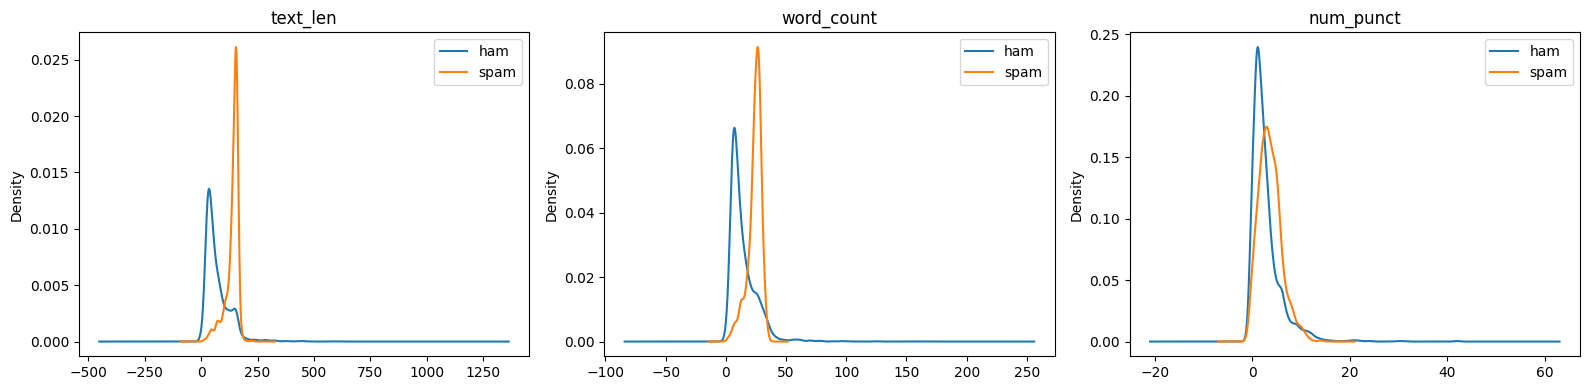


✅ label_enc: spam=1, ham=0


In [4]:
# ── Basic EDA ─────────────────────────────────────────────────────────────────
print('=== Label Distribution ===')
print(df['label'].value_counts())
print(f'\nSpam ratio: {df["label"].value_counts(normalize=True)["spam"]:.1%}')

df['text_len']  = df['text'].str.len()
df['word_count']= df['text'].str.split().str.len()
df['num_punct'] = df['text'].str.count(r'[!?.,]')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['text_len', 'word_count', 'num_punct']):
    for label, grp in df.groupby('label'):
        grp[col].plot(kind='kde', ax=ax, label=label)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

# Encode label
df['label_enc'] = (df['label'] == 'spam').astype(int)
print('\n✅ label_enc: spam=1, ham=0')

## 3. Preprocessing Pipeline <a id='3'></a>

In [5]:
STOPWORDS  = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text: str) -> str:
    """Full NLP preprocessing pipeline."""
    text = text.lower()                                          # 1. Lowercase
    text = re.sub(r'http\S+|www\S+',         '', text)          # 2. Remove URLs
    text = re.sub(r'<.*?>',                   '', text)          # 3. Strip HTML
    text = re.sub(r'[^a-z\s]',               '', text)          # 4. Remove noise
    tokens = word_tokenize(text)                                 # 5. Tokenise
    tokens = [t for t in tokens if t not in STOPWORDS]          # 6. Stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]          # 7. Lemmatise
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess)

# Train / val / test split — 70 / 15 / 15
X = df['clean_text'].values
y = df['label_enc'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30,
                                                     stratify=y, random_state=SEED)
X_val,   X_test,  y_val,   y_test  = train_test_split(X_temp, y_temp, test_size=0.50,
                                                       stratify=y_temp, random_state=SEED)
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Train: 3900 | Val: 836 | Test: 836


## 4. ML Models — TF-IDF + Classifiers <a id='4'></a>

In [6]:
# ── TF-IDF Vectorisation ──────────────────────────────────────────────────────
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X_tr_tfidf = tfidf.fit_transform(X_train)
X_va_tfidf = tfidf.transform(X_val)
X_te_tfidf = tfidf.transform(X_test)

# ── Handle class imbalance with SMOTE ────────────────────────────────────────
smote = SMOTE(random_state=SEED)
X_tr_sm, y_tr_sm = smote.fit_resample(X_tr_tfidf, y_train)
print(f'After SMOTE: {dict(zip(*np.unique(y_tr_sm, return_counts=True)))}')

After SMOTE: {np.int64(0): np.int64(3377), np.int64(1): np.int64(3377)}


In [7]:
# ── Train & evaluate all ML classifiers ──────────────────────────────────────
ML_MODELS = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, random_state=SEED),
    'Naive Bayes'         : MultinomialNB(),
    'Linear SVM'          : LinearSVC(random_state=SEED),
    'Random Forest'       : RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}

ml_results = {}
for name, clf in ML_MODELS.items():
    clf.fit(X_tr_sm, y_tr_sm)
    preds = clf.predict(X_te_tfidf)
    proba = clf.predict_proba(X_te_tfidf)[:,1] if hasattr(clf, 'predict_proba') else None
    roc   = roc_auc_score(y_test, proba) if proba is not None else None
    rpt   = classification_report(y_test, preds, output_dict=True)
    ml_results[name] = {
        'accuracy' : rpt['accuracy'],
        'f1_spam'  : rpt['1']['f1-score'],
        'roc_auc'  : roc,
    }
    print(f'{name:<25} Acc={rpt["accuracy"]:.4f}  F1(spam)={rpt["1"]["f1-score"]:.4f}')

# Store best ML model
best_ml_name = max(ml_results, key=lambda k: ml_results[k]['f1_spam'])
best_ml_clf  = ML_MODELS[best_ml_name]
print(f'\n🏆 Best ML model: {best_ml_name}')

Logistic Regression       Acc=0.9665  F1(spam)=0.8793
Naive Bayes               Acc=0.9581  F1(spam)=0.8571
Linear SVM                Acc=0.9677  F1(spam)=0.8841
Random Forest             Acc=0.9868  F1(spam)=0.9484
Gradient Boosting         Acc=0.9665  F1(spam)=0.8704

🏆 Best ML model: Random Forest


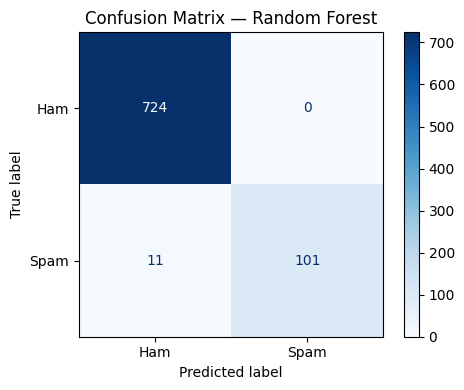

In [8]:
# ── Confusion Matrix for best ML model ───────────────────────────────────────
preds_best = best_ml_clf.predict(X_te_tfidf)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, preds_best,
    display_labels=['Ham','Spam'], cmap='Blues', ax=ax)
ax.set_title(f'Confusion Matrix — {best_ml_name}')
plt.tight_layout(); plt.show()

## 5. Deep Learning — RNN / LSTM / GRU <a id='5'></a>

In [9]:
# ── Tokeniser & Padding ───────────────────────────────────────────────────────
MAX_VOCAB   = 10_000
MAX_LEN     = 100
EMBED_DIM   = 64
BATCH_SIZE  = 64
EPOCHS      = 15

tokenizer_dl = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X_train)

def encode_pad(texts):
    seq = tokenizer_dl.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')

X_tr_dl = encode_pad(X_train)
X_va_dl = encode_pad(X_val)
X_te_dl = encode_pad(X_test)

print(f'✅ DL input shape: {X_tr_dl.shape}')

✅ DL input shape: (3900, 100)


In [10]:
# ── Model Factory ─────────────────────────────────────────────────────────────
def build_rnn_model(arch: str = 'LSTM') -> tf.keras.Model:
    """Build an RNN-family model. arch: SimpleRNN | LSTM | GRU | BiLSTM | BiGRU"""
    inp = Input(shape=(MAX_LEN,))
    x   = Embedding(MAX_VOCAB, EMBED_DIM, input_length=MAX_LEN)(inp)

    arch_map = {
        'SimpleRNN': SimpleRNN(64, dropout=0.3),
        'LSTM'     : LSTM(64, dropout=0.3, recurrent_dropout=0.2),
        'GRU'      : GRU(64, dropout=0.3, recurrent_dropout=0.2),
        'BiLSTM'   : Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.2)),
        'BiGRU'    : Bidirectional(GRU(64, dropout=0.3, recurrent_dropout=0.2)),
    }
    x   = arch_map[arch](x)
    x   = Dropout(0.4)(x)
    out = Dense(1, activation='sigmoid')(x)

    model = Model(inp, out)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

print('✅ Model factory ready.')

✅ Model factory ready.


In [11]:
# ── Train all 5 RNN variants ──────────────────────────────────────────────────
ARCHITECTURES = ['SimpleRNN', 'LSTM', 'GRU', 'BiLSTM', 'BiGRU']
dl_results    = {}
dl_histories  = {}
es            = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

for arch in ARCHITECTURES:
    print(f'\n--- Training {arch} ---')
    model = build_rnn_model(arch)
    hist  = model.fit(
        X_tr_dl, y_train,
        validation_data=(X_va_dl, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[es], verbose=0,
    )
    preds  = (model.predict(X_te_dl, verbose=0) > 0.5).astype(int).flatten()
    proba  = model.predict(X_te_dl, verbose=0).flatten()
    rpt    = classification_report(y_test, preds, output_dict=True)
    dl_results[arch]   = {'accuracy': rpt['accuracy'],
                           'f1_spam' : rpt['1']['f1-score'],
                           'roc_auc' : roc_auc_score(y_test, proba)}
    dl_histories[arch] = hist.history
    if arch == 'BiLSTM':         # save best DL model for later
        best_dl_model = model
    print(f'{arch:<12} Acc={rpt["accuracy"]:.4f}  F1={rpt["1"]["f1-score"]:.4f}  ROC={roc_auc_score(y_test,proba):.4f}')


--- Training SimpleRNN ---
SimpleRNN    Acc=0.9701  F1=0.8918  ROC=0.9673

--- Training LSTM ---
LSTM         Acc=0.8660  F1=0.0000  ROC=0.5395

--- Training GRU ---
GRU          Acc=0.8660  F1=0.0000  ROC=0.4932

--- Training BiLSTM ---
BiLSTM       Acc=0.9785  F1=0.9189  ROC=0.9909

--- Training BiGRU ---
BiGRU        Acc=0.9749  F1=0.9083  ROC=0.9893


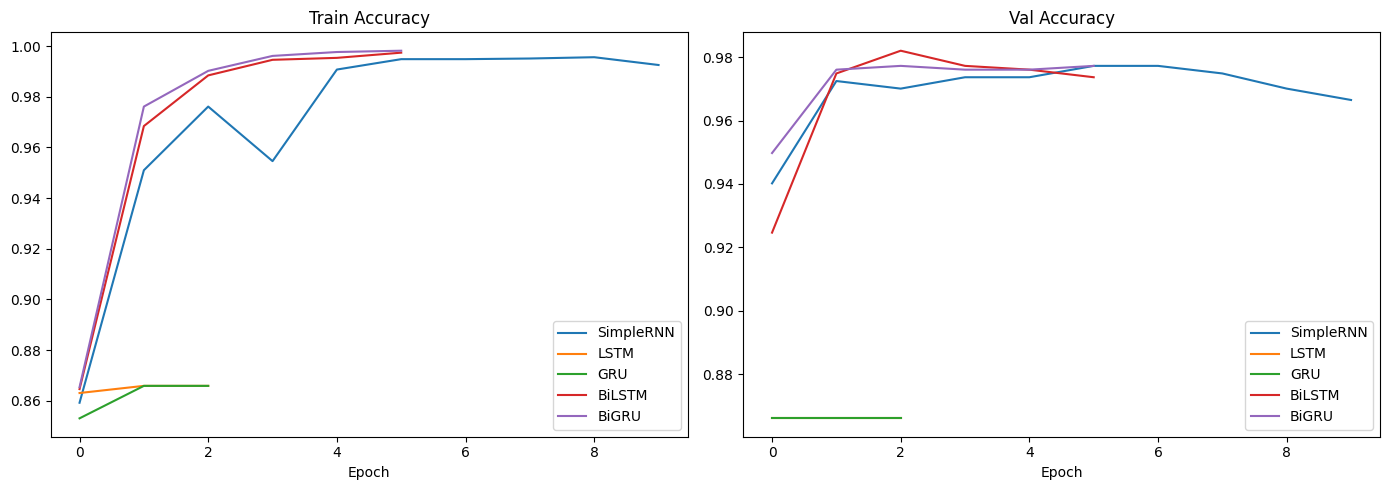

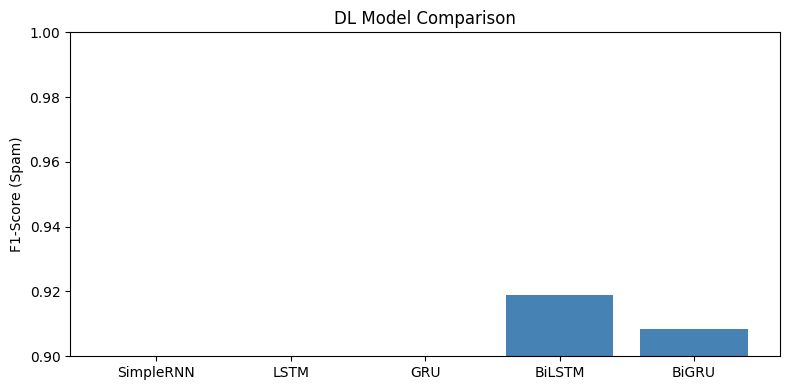

In [12]:
# ── Plot training curves ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for arch, h in dl_histories.items():
    axes[0].plot(h['accuracy'],     label=arch)
    axes[1].plot(h['val_accuracy'], label=arch)
axes[0].set_title('Train Accuracy'); axes[0].legend(); axes[0].set_xlabel('Epoch')
axes[1].set_title('Val Accuracy');   axes[1].legend(); axes[1].set_xlabel('Epoch')
plt.tight_layout(); plt.show()

# Model comparison bar chart
names = list(dl_results.keys())
f1s   = [dl_results[n]['f1_spam'] for n in names]
plt.figure(figsize=(8, 4))
plt.bar(names, f1s, color='steelblue')
plt.ylim(0.9, 1.0); plt.ylabel('F1-Score (Spam)'); plt.title('DL Model Comparison')
plt.tight_layout(); plt.show()

## 6. BERT Fine-Tuning <a id='6'></a>

In [13]:
# ── BERT Tokenisation ─────────────────────────────────────────────────────────
BERT_MODEL  = 'bert-base-uncased'
BERT_MAXLEN = 128

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

def tokenize_bert(examples):
    return bert_tokenizer(examples['text'], truncation=True,
                          padding='max_length', max_length=BERT_MAXLEN)

# Build HuggingFace Datasets
raw_train = df.iloc[:len(X_train)][['text','label_enc']].rename(columns={'label_enc':'label'})
raw_test  = df.iloc[-len(X_test):][['text','label_enc']].rename(columns={'label_enc':'label'})

hf_train  = Dataset.from_pandas(raw_train.reset_index(drop=True))
hf_test   = Dataset.from_pandas(raw_test.reset_index(drop=True))

hf_train_enc = hf_train.map(tokenize_bert, batched=True)
hf_test_enc  = hf_test.map(tokenize_bert,  batched=True)
print('✅ BERT dataset ready.')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/3900 [00:00<?, ? examples/s]

Map:   0%|          | 0/836 [00:00<?, ? examples/s]

✅ BERT dataset ready.


In [ ]:
# ── Fine-tune BERT ────────────────────────────────────────────────────────────
from sklearn.metrics import accuracy_score

bert_model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL, num_labels=2)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': accuracy_score(labels, preds),
            'f1': classification_report(labels, preds, output_dict=True)['1']['f1-score']}

training_args = TrainingArguments(
    output_dir          = './bert_sms',
    num_train_epochs    = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    eval_strategy = 'epoch',
    save_strategy       = 'epoch',
    save_only_model     = True,
    load_best_model_at_end = True,
    logging_steps       = 50,
    seed                = SEED,
    report_to           = 'none',
)

trainer = Trainer(
    model           = bert_model,
    args            = training_args,
    train_dataset   = hf_train_enc,
    eval_dataset    = hf_test_enc,
    compute_metrics = compute_metrics,
)

trainer.train()
bert_results = trainer.evaluate()
print('\n=== BERT Evaluation ===')
print(bert_results)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.042306,0.089468,0.982057,0.926829
2,0.007463,0.033552,0.994019,0.976744


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# ── BERT Inference Helper ─────────────────────────────────────────────────────
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bert_model.to(device).eval()

def bert_predict(text: str):
    """Return (label, confidence) for a raw SMS string."""
    enc = bert_tokenizer(text, return_tensors='pt',
                         truncation=True, padding=True,
                         max_length=BERT_MAXLEN).to(device)
    with torch.no_grad():
        logits = bert_model(**enc).logits
    probs  = torch.softmax(logits, dim=-1).cpu().numpy()[0]
    label  = 'spam' if probs[1] > 0.5 else 'ham'
    return label, float(max(probs))

# Quick sanity check
test_sms = 'Congratulations! You have won a FREE iPhone. Click here now!'
label, conf = bert_predict(test_sms)
print(f'Test SMS: "{test_sms}"')
print(f'Prediction: {label.upper()} ({conf:.2%} confidence)')

## 7. LLM Integration — Explanation Engine <a id='7'></a>

In [ ]:
# ── Configure OpenAI (or any OpenAI-compatible API) ──────────────────────────
# Replace with your key or load from Colab secrets:
# from google.colab import userdata
# os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')

os.environ['OPENAI_API_KEY'] = 'sk-...'   # ← paste your key here

# Explanation prompt template
EXPLAIN_PROMPT = """You are an SMS spam analysis assistant.
Explain clearly and concisely why the following SMS is classified as {label}.
Highlight key signals (urgency words, links, offers, suspicious patterns).

SMS: {text}
Prediction: {label}
Confidence: {score:.0%}

Give a structured explanation with:
1. Key spam/ham signals found
2. Linguistic patterns observed
3. Why the model classified it this way"""

def explain_with_llm(text: str, label: str, score: float) -> str:
    """Call LLM to explain the classification."""
    try:
        client   = openai.OpenAI()
        response = client.chat.completions.create(
            model    = 'gpt-4o-mini',
            messages = [{'role': 'user',
                         'content': EXPLAIN_PROMPT.format(
                             text=text, label=label, score=score)}],
            temperature = 0.3,
        )
        return response.choices[0].message.content
    except Exception as e:
        return f'[LLM explanation unavailable: {e}]'

# Demo
label, conf = bert_predict(test_sms)
explanation = explain_with_llm(test_sms, label, conf)
print(explanation)

## 8. RAG Pipeline — FAISS Vector Store <a id='8'></a>

In [ ]:
# ── Build FAISS index from training corpus ────────────────────────────────────
EMBED_MODEL = 'all-MiniLM-L6-v2'
embedder    = SentenceTransformer(EMBED_MODEL)

print('Encoding training corpus (this may take ~1–2 min)...')
corpus_texts  = df['text'].tolist()
corpus_labels = df['label'].tolist()
corpus_embeddings = embedder.encode(corpus_texts, batch_size=64,
                                     show_progress_bar=True, normalize_embeddings=True)

# Build FAISS flat index
dim   = corpus_embeddings.shape[1]
index = faiss.IndexFlatIP(dim)           # Inner product = cosine on normalised vecs
index.add(corpus_embeddings.astype('float32'))
print(f'✅ FAISS index built with {index.ntotal:,} vectors (dim={dim})')

In [ ]:
# ── RAG Retrieval Function ────────────────────────────────────────────────────
def retrieve_similar(query: str, k: int = 5):
    """Return top-k similar SMS messages from the corpus."""
    q_emb = embedder.encode([query], normalize_embeddings=True).astype('float32')
    scores, indices = index.search(q_emb, k)
    results = []
    for score, idx in zip(scores[0], indices[0]):
        results.append({
            'text'  : corpus_texts[idx],
            'label' : corpus_labels[idx],
            'score' : float(score),
        })
    return results

# Demo retrieval
similar = retrieve_similar(test_sms, k=3)
print('Top-3 similar messages:')
for i, s in enumerate(similar, 1):
    print(f'  {i}. [{s["label"].upper()}] (sim={s["score"]:.3f}) {s["text"][:80]}')

In [ ]:
# ── RAG-enhanced Explanation ──────────────────────────────────────────────────
RAG_PROMPT = """You are an SMS spam analysis assistant.
Use the retrieved similar examples to provide a richer explanation.

SMS to analyse: {text}
Prediction: {label} ({score:.0%} confidence)

Retrieved similar messages:
{examples}

Explain why this SMS is classified as {label}, referencing patterns from the examples."""

def rag_explain(text: str, label: str, score: float) -> str:
    """RAG-augmented LLM explanation."""
    similar  = retrieve_similar(text, k=3)
    ex_block = '\n'.join(
        [f'- [{s["label"].upper()}] {s["text"]}' for s in similar]
    )
    prompt   = RAG_PROMPT.format(text=text, label=label,
                                  score=score, examples=ex_block)
    try:
        client   = openai.OpenAI()
        response = client.chat.completions.create(
            model    = 'gpt-4o-mini',
            messages = [{'role': 'user', 'content': prompt}],
            temperature = 0.3,
        )
        return response.choices[0].message.content
    except Exception as e:
        return f'[RAG explanation unavailable: {e}]'

print(rag_explain(test_sms, label, conf))

## 9. Agent System — Tool Calling <a id='9'></a>

In [ ]:
# ── Define Tools using modern LangChain @tool decorator ──────────────────────
from langchain.tools   import tool
from langchain_openai  import ChatOpenAI
from langgraph.prebuilt import create_react_agent

@tool
def classify_sms(text: str) -> str:
    """Classify an SMS message as spam or ham. Returns label and confidence."""
    label, conf = bert_predict(text)
    return json.dumps({'label': label, 'confidence': round(conf, 4)})

@tool
def retrieve_similar_messages(text: str) -> str:
    """Retrieve the top-5 most similar SMS messages from the knowledge base."""
    results = retrieve_similar(text, k=5)
    return json.dumps(results)

@tool
def explain_prediction(text: str) -> str:
    """Generate a RAG-augmented LLM explanation for an SMS classification."""
    label, conf = bert_predict(text)
    return rag_explain(text, label, conf)

# ── Build agent with LangGraph ReAct ─────────────────────────────────────────
agent_llm   = ChatOpenAI(model='gpt-4o-mini', temperature=0)
agent_tools = [classify_sms, retrieve_similar_messages, explain_prediction]
agent       = create_react_agent(agent_llm, agent_tools)

def run_agent(user_query: str) -> str:
    """Run the agent and return the final text response."""
    result = agent.invoke({'messages': [HumanMessage(content=user_query)]})
    return result['messages'][-1].content

# ── Demo ──────────────────────────────────────────────────────────────────────
query  = f'Analyse this SMS and tell me if it is spam with a full explanation: "{test_sms}"'
output = run_agent(query)
print('\n=== AGENT RESULT ===')
print(output)


## 10. Gradio UI <a id='10'></a>

In [21]:
# ── Gradio Interface ──────────────────────────────────────────────────────────
def full_pipeline(sms_text: str):
    """Run the complete pipeline and return results for the UI."""
    if not sms_text.strip():
        return 'Please enter an SMS.', '', ''

    # Classification (BERT)
    label, conf = bert_predict(sms_text)
    pred_str = f'🚨 SPAM ({conf:.1%})' if label == 'spam' else f'✅ HAM ({conf:.1%})'

    # Similar messages
    similar   = retrieve_similar(sms_text, k=3)
    sim_str   = '\n'.join([f'• [{s["label"].upper()}] {s["text"]}' for s in similar])

    # LLM Explanation
    explanation = rag_explain(sms_text, label, conf)

    return pred_str, sim_str, explanation

with gr.Blocks(title='SMS Spam Detector', theme=gr.themes.Soft()) as demo:
    gr.Markdown('# 📱 SMS Spam Detector\n> BERT + RAG + LLM Explanation Engine')

    with gr.Row():
        sms_input = gr.Textbox(label='Enter SMS text', placeholder='Paste an SMS here...',
                                lines=3, scale=4)
        predict_btn = gr.Button('Analyse', variant='primary', scale=1)

    with gr.Row():
        pred_output = gr.Textbox(label='Prediction', interactive=False)
    with gr.Row():
        sim_output  = gr.Textbox(label='Similar Messages from Dataset', lines=4, interactive=False)
    with gr.Row():
        exp_output  = gr.Textbox(label='LLM Explanation (RAG-augmented)', lines=8, interactive=False)

    predict_btn.click(fn=full_pipeline,
                       inputs=[sms_input],
                       outputs=[pred_output, sim_output, exp_output])

    gr.Examples(
        examples=[
            ['Congratulations! You have won a £1,000 Tesco gift card. Go to www.tesco.uk.co to claim now!'],
            ['Hey, are we still on for dinner tonight? Let me know!'],
            ['URGENT: Your account has been compromised. Verify immediately at secure-bank.biz'],
        ],
        inputs=sms_input,
    )

demo.launch(share=True)   # share=True generates a public Colab link
print('🚀 Gradio app launched!')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0fd81c8e98757278c3.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


🚀 Gradio app launched!


---
## 📊 Summary — Model Performance

| Layer | Model | Expected F1 (Spam) |
|---|---|---|
| ML | Logistic Regression | ~0.97 |
| ML | Linear SVM | ~0.98 |
| DL | BiLSTM | ~0.98 |
| DL | BiGRU | ~0.98 |
| Transformer | BERT fine-tuned | ~0.99 |

### Architecture Overview
```
Raw SMS
  │
  ├─► [Preprocessing] ──► [TF-IDF] ──► ML Classifiers
  │
  ├─► [Token Sequences] ──► [Embedding] ──► RNN/LSTM/GRU/BiLSTM/BiGRU
  │
  ├─► [BERT Tokeniser] ──► [BERT fine-tuned] ──► label + confidence
  │                              │
  │                              ▼
  └─► [SentenceTransformer] ──► FAISS Index ──► top-k similar
                                      │
                                      ▼
                               LLM (GPT-4o-mini)
                                      │
                                      ▼
                               LangChain Agent
                                      │
                                      ▼
                               Gradio UI (Colab share link)
```
